<a href="https://colab.research.google.com/github/a01286849-glitch/damian-garza-kosikova-A01286849/blob/main/A10FINALL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# What Is Associated with Music Virality and Streaming Reach?
**Damián Garza Kosikova**  
Visualization of Data for Decision Making · Final Executive Analysis

## Table of Contents
Click a study to jump directly to its figure and Python code in Google Colab.

| Section | Direct link |
|---|---|
| Setup | [Connect Google Drive and load the CSV](#scrollTo=drive_setup) |
| Dataset | [Context, quality checks, and variables](#scrollTo=dataset_description) |
| Roadmap | [Eight questions, figures, and calculated findings](#scrollTo=roadmap) |
| Study 1 | [How concentrated is streaming reach? — Histogram](#scrollTo=study_one) |
| Study 2 | [How does viral rate differ by genre? — Ranked dot plot](#scrollTo=study_two) |
| Study 3 | [How does danceability differ by viral status? — Box plot](#scrollTo=study_three) |
| Study 4 | [How does the energy distribution differ by genre? — Violin plot](#scrollTo=study_four) |
| Study 5 | [How does viral rate differ across release-year cohorts? — Line chart](#scrollTo=study_five) |
| Study 6 | [Which audio features correlate with streaming reach? — Heatmap](#scrollTo=study_six) |
| Study 7 | [Do viral and non-viral songs differ in duration? — ECDF](#scrollTo=study_seven) |
| Study 8 | [How well do three audio features explain streams? — Regression](#scrollTo=study_eight) |
| Conclusions | [Connected findings and limitations](#scrollTo=conclusions) |

**Run instructions:** Open this notebook in Colab and run the cells from top to bottom. The CSV path is `/content/drive/MyDrive/viral_songs.csv`. No figures or tables are saved automatically.

In [ ]:
# Connect Google Drive.
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Import libraries before reading the CSV.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from IPython.display import display

DATA_PATH = '/content/drive/MyDrive/viral_songs.csv'
df = pd.read_csv(DATA_PATH)

sns.set_theme(style='whitegrid', font_scale=1.1)
plt.rcParams['figure.figsize'] = (10, 6)
BLUE, TEAL, GRAY = 'steelblue', 'teal', 'gray'

# Extra columns used in the analysis.
df['status'] = df['viral'].map({0: 'Non-viral', 1: 'Viral'})
df['duration_min'] = df['duration_sec'] / 60
df['log_streams'] = np.log10(df['streams'])

print('Songs:', len(df))
print('Original variables:', len(df.columns) - 3)
print('Missing values:', df.isna().sum().sum())
display(df.head())

Songs: 10000
Original variables: 17
Missing values: 0


,track_id,track_name,artist,genre,release_year,duration_sec,danceability,energy,valence,tempo_bpm,acousticness,instrumentalness,speechiness,liveness,loudness_db,streams,viral,status,duration_min,log_streams
0,track_00001,Track_00001,Artist_1519,Pop,2013,237,0.760,0.703,0.747,140.8,0.115,0.103,0.206,0.272,-9.41,661412,1,Viral,3.950000,5.820472
1,track_00002,Track_00002,Artist_0458,Electronic,2018,239,0.436,0.934,0.672,105.1,0.016,0.002,0.024,0.000,-9.89,1114175,1,Viral,3.983333,6.046953
2,track_00003,Track_00003,Artist_1386,Hip-Hop,2014,148,0.642,0.725,0.460,90.6,0.010,0.520,0.079,0.053,-5.53,105832,1,Viral,2.466667,5.024617
3,track_00004,Track_00004,Artist_0865,Classical,2012,216,0.326,0.456,0.299,71.3,0.966,0.042,0.000,0.074,-11.39,915397,0,Non-viral,3.600000,5.961609
4,track_00005,Track_00005,Artist_0192,Pop,2011,277,0.599,0.683,0.700,132.6,0.078,0.113,0.000,0.036,-5.56,3690733,1,Viral,4.616667,6.567113


## Dataset and variables
**Source:** the provided `viral_songs.csv`.from kaggle
**Context:** audio features, stream counts, and a supplied viral label for 10,000 track records with 17 original columns. One row represents one track.

The stream-count time window and the definition of “viral” are unknown. Release years identify cohorts; this is not a record of streaming activity over time. All results describe this dataset.

In [ ]:
variables = pd.DataFrame([
    ['track_id', 'Unique track identifier', 'Categorical identifier', 'Track ID'],
    ['genre', 'Music genre', 'Categorical', 'Genre names'],
    ['viral', 'Supplied viral label', 'Categorical: binary', '0 = no; 1 = yes'],
    ['release_year', 'Year of release', 'Numerical: discrete, time-related', 'Year'],
    ['streams', 'Recorded streams', 'Numerical: discrete', 'Stream count'],
    ['danceability', 'Danceability score', 'Numerical: continuous', '0–1'],
    ['energy', 'Energy score', 'Numerical: continuous', '0–1'],
    ['valence', 'Musical positivity score', 'Numerical: continuous', '0–1'],
    ['tempo_bpm', 'Tempo', 'Numerical: continuous', 'Beats per minute'],
    ['acousticness', 'Acousticness score', 'Numerical: continuous', '0–1'],
    ['loudness_db', 'Loudness', 'Numerical: continuous', 'Decibels'],
    ['duration_sec', 'Original duration', 'Numerical: discrete', 'Seconds'],
    ['duration_min', 'Duration divided by 60', 'Numerical: derived', 'Minutes'],
    ['log_streams', 'Base-10 log of streams', 'Numerical: derived', 'log10(streams)'],
    ['status', 'Readable viral label', 'Categorical: binary', 'Non-viral / Viral'],
], columns=['Variable', 'Meaning', 'Type', 'Unit / Categories'])
display(variables)

,Variable,Meaning,Type,Unit / Categories
0,track_id,Unique track identifier,Categorical identifier,Track ID
1,genre,Music genre,Categorical,Genre names
2,viral,Supplied viral label,Categorical: binary,0 = no; 1 = yes
3,release_year,Year of release,"Numerical: discrete, time-related",Year
4,streams,Recorded streams,Numerical: discrete,Stream count
5,danceability,Danceability score,Numerical: continuous,0–1
6,energy,Energy score,Numerical: continuous,0–1
7,valence,Musical positivity score,Numerical: continuous,0–1
8,tempo_bpm,Tempo,Numerical: continuous,Beats per minute
9,acousticness,Acousticness score,Numerical: continuous,0–1


In [ ]:
# 3. Calculate the summaries used in the roadmap and charts.
genre_rates = df.groupby('genre')['viral'].mean().sort_values(ascending=False) * 100
dance_medians = df.groupby('status')['danceability'].median()
energy_medians = df.groupby('genre')['energy'].median().sort_values(ascending=False)
year_rates = df.groupby('release_year')['viral'].mean() * 100
duration_medians = df.groupby('status')['duration_min'].median()
features = ['danceability', 'energy', 'valence', 'tempo_bpm', 'acousticness', 'loudness_db']
correlations = df[features + ['log_streams']].corr()
stream_correlations = correlations.loc[features, 'log_streams']
strongest = stream_correlations.abs().idxmax()
top_count = int(np.ceil(len(df) * 0.01))
top_share = df['streams'].nlargest(top_count).sum() / df['streams'].sum() * 100

# Study 8 uses a basic multiple linear regression, fitted to this dataset.
# R² below measures in-sample fit, not performance on new songs.
predictors = ['danceability', 'energy', 'valence']
X = df[predictors]
y = df['log_streams']
model = LinearRegression()
model.fit(X, y)
predicted = model.predict(X)
r_squared = model.score(X, y)
residuals = y - predicted
outliers = residuals.abs() > 3 * residuals.std()

## Analytical roadmap
The eight studies move from streaming reach to viral profiles, then evaluate a basic model of reach. Findings in this table are calculated from the CSV.

In [ ]:
questions = [
    'How concentrated are streams across tracks?',
    'How does viral rate differ by genre?',
    'How does danceability differ by viral status?',
    'How does energy differ across genres?',
    'How does viral rate differ across release-year cohorts?',
    'Which selected audio features correlate most with log streaming reach?',
    'Do viral and non-viral tracks differ in duration?',
    'How well do danceability, energy, and valence explain log streaming reach?'
]
figures = ['Histogram', 'Ranked dot plot', 'Box plot', 'Violin plot',
           'Cohort line chart', 'Correlation heatmap', 'ECDF',
           'Regression scatter with a conditional fitted line']
findings = [
    f'Top 1% of tracks: {top_share:.1f}% of streams.',
    f'{genre_rates.index[0]} has the highest viral rate: {genre_rates.iloc[0]:.1f}%.',
    f"Median danceability: viral {dance_medians['Viral']:.3f}; non-viral {dance_medians['Non-viral']:.3f}.",
    f'{energy_medians.index[0]} has the highest median energy.',
    f'Cohort rates span {year_rates.max() - year_rates.min():.1f} percentage points.',
    f'Strongest absolute correlation: {strongest}, r = {stream_correlations[strongest]:.3f}.',
    f"Median duration: viral {duration_medians['Viral']:.2f}; non-viral {duration_medians['Non-viral']:.2f} minutes.",
    f'The model explains {r_squared:.1%} of log-stream variation in this dataset.'
]
roadmap = pd.DataFrame({'Study': range(1, 9), 'Question': questions,
                        'Figure': figures, 'Main insight': findings})
display(roadmap)

,Study,Question,Figure,Main insight
0,1,How concentrated are streams across tracks?,Histogram,Top 1% of tracks: 29.5% of streams.
1,2,How does viral rate differ by genre?,Ranked dot plot,Latin has the highest viral rate: 64.7%.
2,3,How does danceability differ by viral status?,Box plot,Median danceability: viral 0.720; non-viral 0....
3,4,How does energy differ across genres?,Violin plot,Rock has the highest median energy.
4,5,How does viral rate differ across release-year...,Cohort line chart,Cohort rates span 4.9 percentage points.
5,6,Which selected audio features correlate most w...,Correlation heatmap,"Strongest absolute correlation: danceability, ..."
6,7,Do viral and non-viral tracks differ in duration?,ECDF,Median duration: viral 3.47; non-viral 3.48 mi...
7,8,"How well do danceability, energy, and valence ...",Regression scatter with a conditional fitted line,The model explains 6.8% of log-stream variatio...


## Study 1 — Streaming reach

**Question:** How concentrated are streams across tracks?

**Analysis and figure:** Compare stream counts and the share held by the top 1%. A histogram shows the distribution. A log axis keeps very large counts readable.

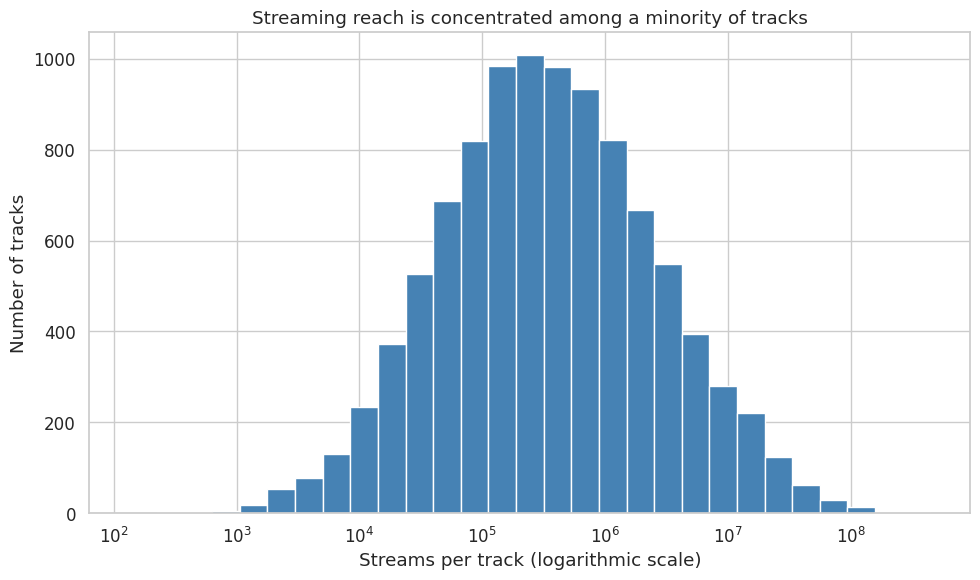

In [ ]:
plt.figure()
plt.hist(df['streams'], bins=np.geomspace(df['streams'].min(), df['streams'].max(), 30),
         color=BLUE, edgecolor='white')
plt.xscale('log')
plt.title('Streaming reach is concentrated among a minority of tracks')
plt.xlabel('Streams per track (logarithmic scale)')
plt.ylabel('Number of tracks')
plt.tight_layout()
plt.show()

### Key insights

In [ ]:
print('Insight 1:', findings[0])
print(f"Insight 2: Mean streams = {df['streams'].mean():,.0f}; median = {df['streams'].median():,.0f}. High counts pull the mean upward.")

Insight 1: Top 1% of tracks: 29.5% of streams.
Insight 2: Mean streams = 2,415,685; median = 329,058. High counts pull the mean upward.


## Study 2 — Viral rate by genre

**Question:** How does viral rate differ by genre?

**Analysis and figure:** Compare viral tracks divided by all tracks within each genre. A dot plot ranks percentages fairly even when genre sample sizes differ.

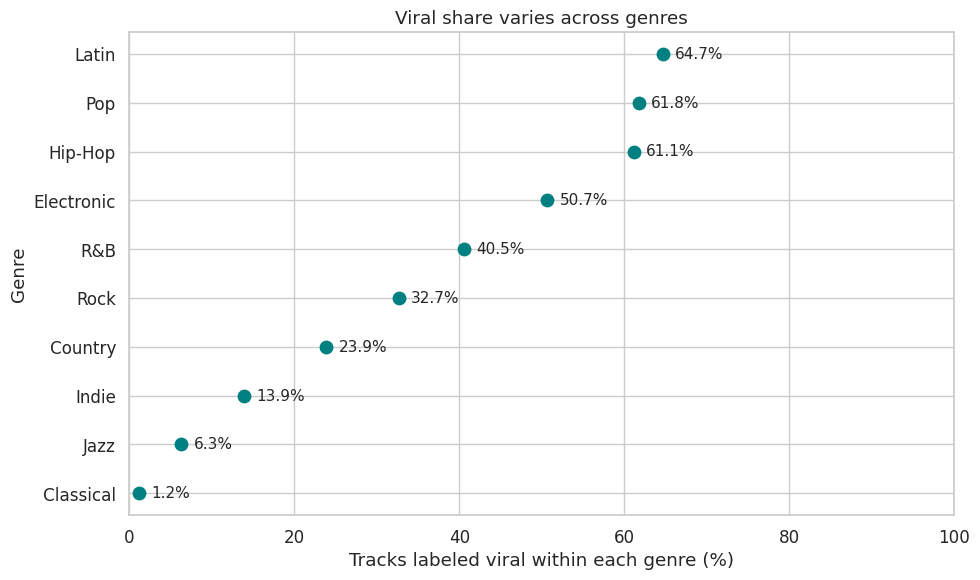

In [ ]:
plt.figure()
plt.scatter(genre_rates.values, genre_rates.index, color=TEAL, s=80)
plt.gca().invert_yaxis()
plt.xlim(0, 100)
plt.title('Viral share varies across genres')
plt.xlabel('Tracks labeled viral within each genre (%)')
plt.ylabel('Genre')
for rate, genre in zip(genre_rates.values, genre_rates.index):
    plt.text(rate + 1.5, genre, f'{rate:.1f}%', va='center', fontsize=11)
plt.tight_layout()
plt.show()

### Key insights

In [ ]:
print('Insight 1:', findings[1])
print(f'Insight 2: {genre_rates.index[-1]} has the lowest rate ({genre_rates.iloc[-1]:.1f}%). Genre differences do not prove causation.')

Insight 1: Latin has the highest viral rate: 64.7%.
Insight 2: Classical has the lowest rate (1.2%). Genre differences do not prove causation.


## Study 3 — Danceability by viral status

**Question:** How does danceability differ by viral status?

**Analysis and figure:** Compare medians and spread. A box plot shows the middle 50% of each group and its median.

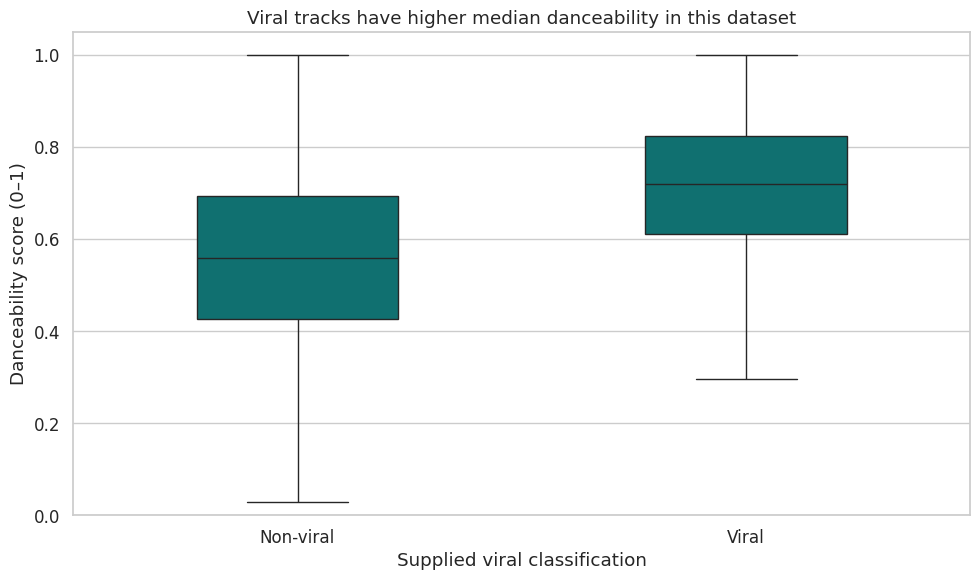

In [ ]:
plt.figure()
sns.boxplot(data=df, x='status', y='danceability', order=['Non-viral', 'Viral'],
            color=TEAL, width=0.45, showfliers=False)
plt.title('Viral tracks have higher median danceability in this dataset')
plt.xlabel('Supplied viral classification')
plt.ylabel('Danceability score (0–1)')
plt.ylim(0, 1.05)
plt.tight_layout()
plt.show()

### Key insights

In [ ]:
print('Insight 1:', findings[2])
print('Insight 2: The groups overlap, so danceability alone does not separate all viral and non-viral tracks.')
print('Chart note: Outlier markers are hidden for readability; no rows were removed.')

Insight 1: Median danceability: viral 0.720; non-viral 0.559.
Insight 2: The groups overlap, so danceability alone does not separate all viral and non-viral tracks.
Chart note: Outlier markers are hidden for readability; no rows were removed.


## Study 4 — Energy by genre

**Question:** How does energy differ across genres?

**Analysis and figure:** Compare full energy distributions. Violin width shows where scores concentrate; inner lines show quartiles. Width does not represent sample size.

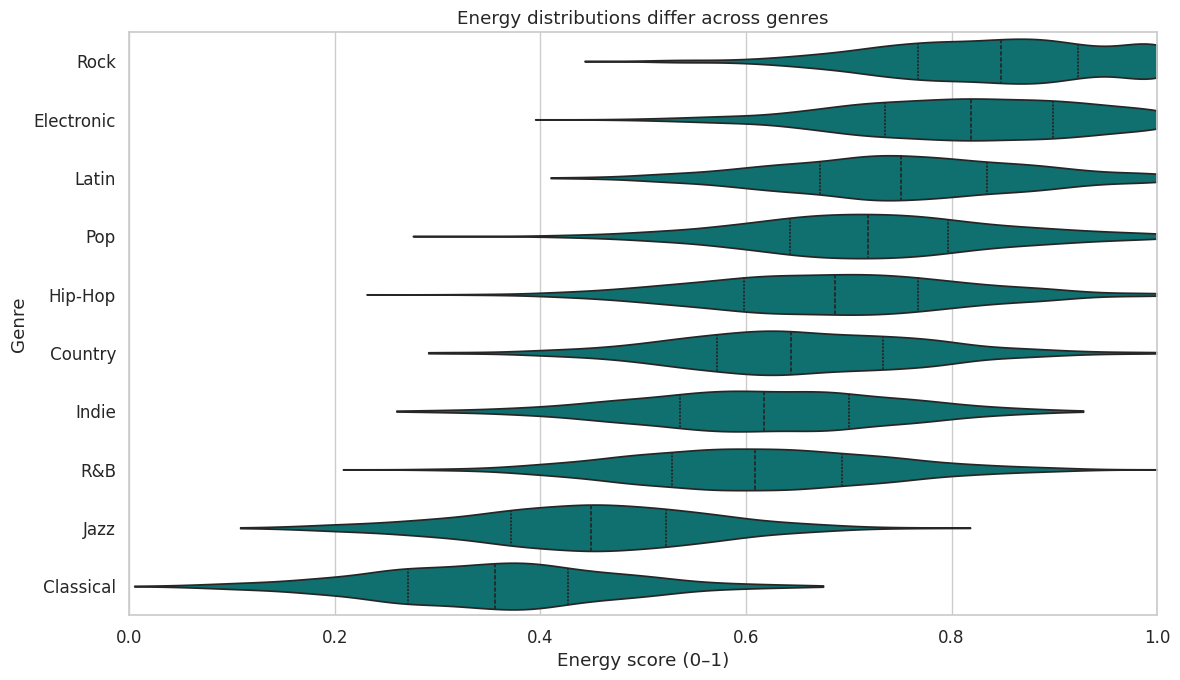

In [ ]:
plt.figure(figsize=(12, 7))
sns.violinplot(data=df, x='energy', y='genre', order=energy_medians.index,
               color=TEAL, inner='quartile', cut=0)
plt.title('Energy distributions differ across genres')
plt.xlabel('Energy score (0–1)')
plt.ylabel('Genre')
plt.xlim(0, 1)
plt.tight_layout()
plt.show()

### Key insights

In [ ]:
print(f'Insight 1: {energy_medians.index[0]} has the highest median energy ({energy_medians.iloc[0]:.3f}).')
print(f'Insight 2: {energy_medians.index[-1]} has the lowest median energy ({energy_medians.iloc[-1]:.3f}); genre context matters when interpreting audio profiles.')

Insight 1: Rock has the highest median energy (0.849).
Insight 2: Classical has the lowest median energy (0.356); genre context matters when interpreting audio profiles.


## Study 5 — Viral rate by release cohort

**Question:** How does viral rate differ across release-year cohorts?

**Analysis and figure:** Compare the percentage labeled viral in each release-year group. Connected points keep the years in order. These are release cohorts, not historical streaming measurements.

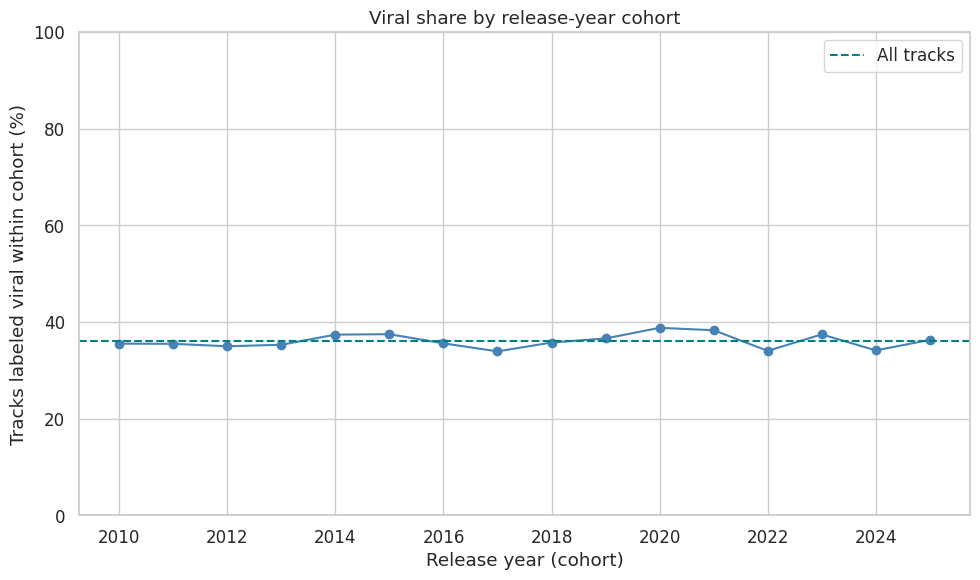

In [ ]:
plt.figure()
plt.plot(year_rates.index, year_rates.values, marker='o', color=BLUE)
plt.axhline(df['viral'].mean() * 100, color=TEAL, linestyle='--', label='All tracks')
plt.title('Viral share by release-year cohort')
plt.xlabel('Release year (cohort)')
plt.ylabel('Tracks labeled viral within cohort (%)')
plt.xticks(year_rates.index[::2])
plt.ylim(0, 100)
plt.legend()
plt.tight_layout()
plt.show()

### Key insights

In [ ]:
print('Insight 1:', findings[4])
print('Insight 2: The cohort differences are modest. They do not show how a song becomes viral over time.')

Insight 1: Cohort rates span 4.9 percentage points.
Insight 2: The cohort differences are modest. They do not show how a song becomes viral over time.


## Study 6 — Audio features and streaming reach

**Question:** Which selected audio features correlate most with log streaming reach?

**Analysis and figure:** Calculate Pearson correlations. A heatmap shows the direction and strength of linear associations on a common scale.

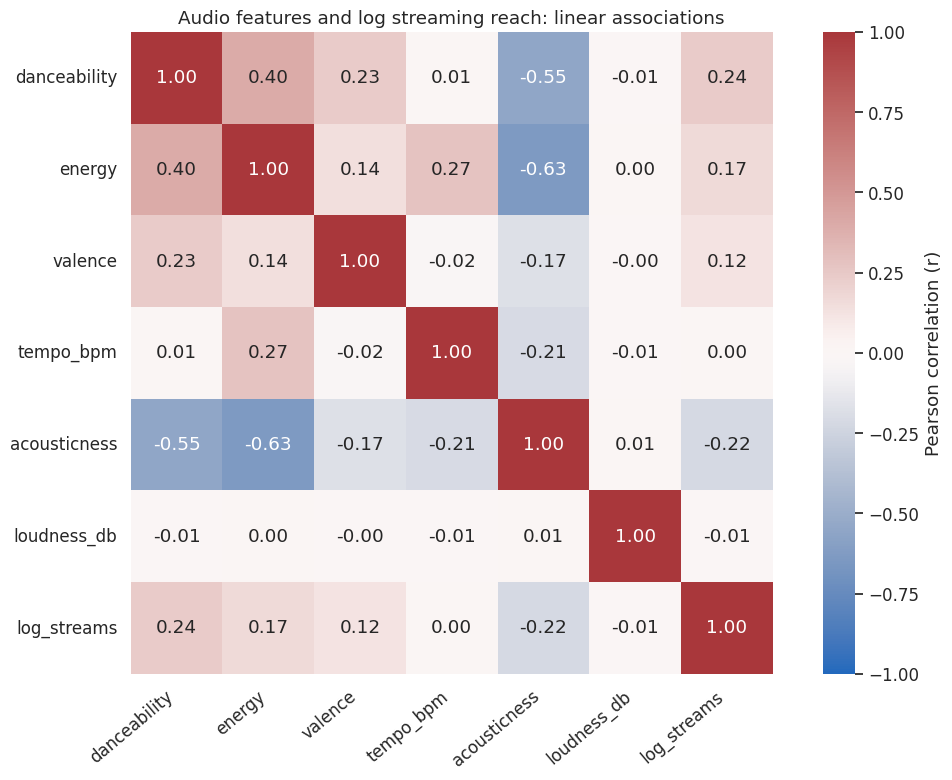

In [ ]:
plt.figure(figsize=(11, 8))
sns.heatmap(correlations, annot=True, fmt='.2f', cmap='vlag',
            vmin=-1, vmax=1, center=0, square=True,
            cbar_kws={'label': 'Pearson correlation (r)'})
plt.title('Audio features and log streaming reach: linear associations')
plt.xticks(rotation=40, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

### Key insights

In [ ]:
print('Insight 1:', findings[5])
print('Insight 2: These are unadjusted associations. Correlation does not prove that a feature causes higher streams.')

Insight 1: Strongest absolute correlation: danceability, r = 0.241.
Insight 2: These are unadjusted associations. Correlation does not prove that a feature causes higher streams.


## Study 7 — Duration distributions

**Question:** Do viral and non-viral tracks differ in duration?

**Analysis and figure:** Compare cumulative duration distributions. An ECDF shows the share of tracks at or below each duration without choosing histogram bins.

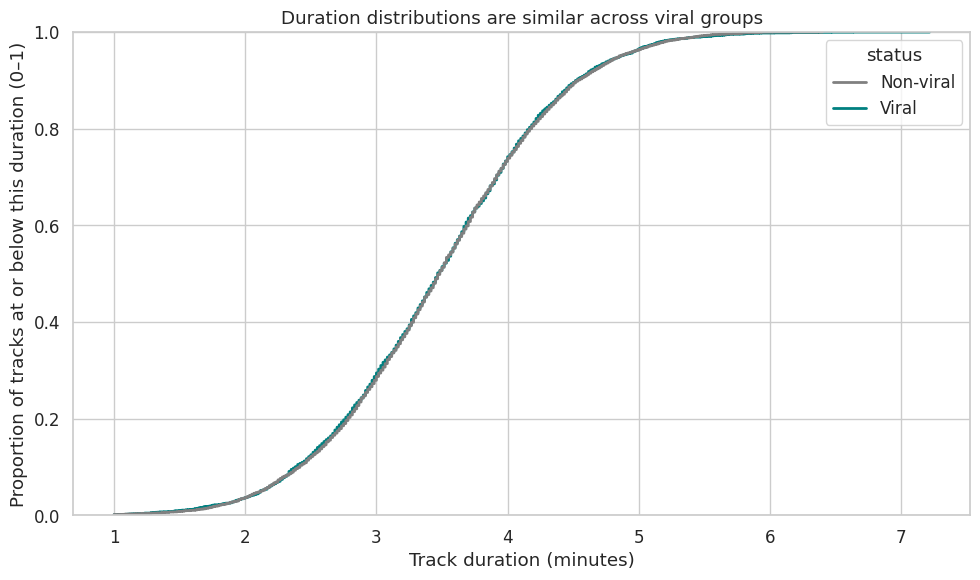

In [ ]:
plt.figure()
sns.ecdfplot(data=df, x='duration_min', hue='status',
             hue_order=['Non-viral', 'Viral'], palette=[GRAY, TEAL], linewidth=2)
plt.title('Duration distributions are similar across viral groups')
plt.xlabel('Track duration (minutes)')
plt.ylabel('Proportion of tracks at or below this duration (0–1)')
plt.tight_layout()
plt.show()

### Key insights

In [ ]:
print('Insight 1:', findings[6])
print('Insight 2: The cumulative curves largely overlap, suggesting duration provides little separation in this dataset.')
print('Reading the chart: A value of 0.50 at 3.5 minutes means 50% of that group lasts at most 3.5 minutes.')

Insight 1: Median duration: viral 3.47; non-viral 3.48 minutes.
Insight 2: The cumulative curves largely overlap, suggesting duration provides little separation in this dataset.
Reading the chart: A value of 0.50 at 3.5 minutes means 50% of that group lasts at most 3.5 minutes.


## Study 8 — Regression model

**Question:** How well do danceability, energy, and valence explain log streaming reach?

**Analysis and figure:** Fit an ordinary least-squares model with three explanatory variables. The outcome is log10(streams). The scatter plot shows a fitted line at fixed values of the other predictors; residuals are reviewed numerically, without adding a second graph.

log10(streams) = 4.572 +0.873*danceability +0.385*energy +0.314*valence
R-squared: 0.068
Variation explained in this dataset: 6.8%
Pearson r, danceability vs log10(streams): 0.241


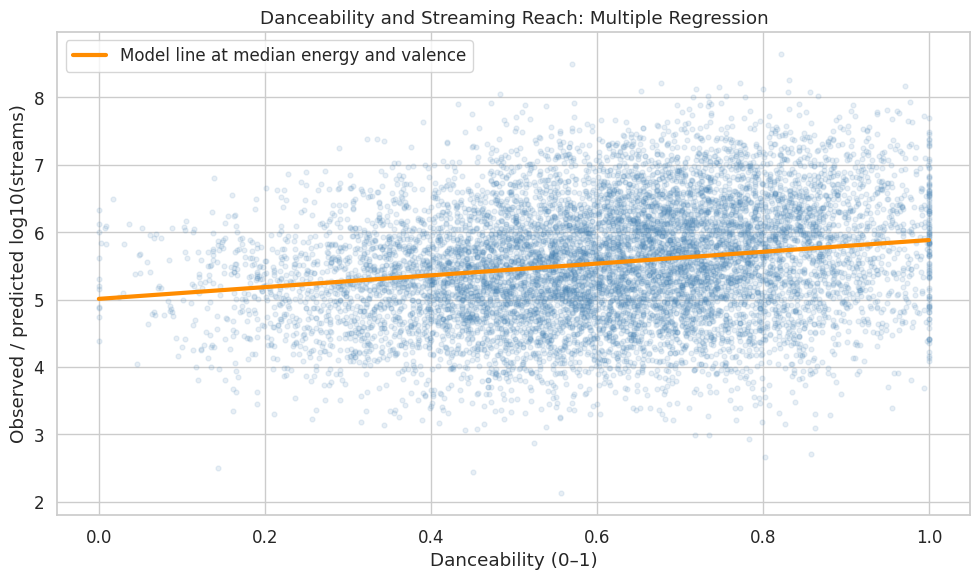

,danceability,energy,valence
0,0.624,0.669,0.582


Predicted log10(streams): 5.556
Back-transformed prediction: 360,016 streams
Mean residual: -0.000000
Residual standard deviation: 0.843 log10 units
Potential outliers: 17


,track_id,streams,residual
637,track_00638,317562436,2.964285
1024,track_01025,113138131,2.626313
1167,track_01168,162740944,2.592774
1728,track_01729,518,-3.010428
2223,track_02224,457,-2.971815
2319,track_02320,998,-2.727947
2536,track_02537,277,-2.969598
3778,track_03779,867,-2.749416
5039,track_05040,1638,-2.575034
5736,track_05737,163017304,2.629718


In [ ]:
# Y is log10(streams). X contains three audio characteristics.
X = df[['danceability', 'energy', 'valence']]
y = df['log_streams']
model = LinearRegression().fit(X, y)
predicted = model.predict(X)
r_squared = model.score(X, y)

# Coefficients and fitted equation.
b_dance, b_energy, b_valence = model.coef_
print(f'log10(streams) = {model.intercept_:.3f} {b_dance:+.3f}*danceability {b_energy:+.3f}*energy {b_valence:+.3f}*valence')
print(f'R-squared: {r_squared:.3f}')
print(f'Variation explained in this dataset: {r_squared:.1%}')
print(f"Pearson r, danceability vs log10(streams): {df['danceability'].corr(y):.3f}")

# Draw ONE regression graph. Fix energy and valence at their medians.
line = pd.DataFrame({
    'danceability': np.linspace(0, 1, 100),
    'energy': df['energy'].median(),
    'valence': df['valence'].median()
})
plt.figure()
plt.scatter(df['danceability'], y, alpha=0.12, s=12, color=BLUE)
plt.plot(line['danceability'], model.predict(line), color='darkorange',
         linewidth=3, label='Model line at median energy and valence')
plt.title('Danceability and Streaming Reach: Multiple Regression')
plt.xlabel('Danceability (0–1)')
plt.ylabel('Observed / predicted log10(streams)')
plt.legend()
plt.tight_layout()
plt.show()

# Example prediction for a song with median feature scores.
example = X.median().to_frame().T
prediction = model.predict(example)[0]
display(example)
print(f'Predicted log10(streams): {prediction:.3f}')
print(f'Back-transformed prediction: {10 ** prediction:,.0f} streams')

# Residual review, using numbers and a table instead of another graph.
residuals = y - predicted
outliers = residuals.abs() > 3 * residuals.std()
print(f'Mean residual: {residuals.mean():.6f}')
print(f'Residual standard deviation: {residuals.std():.3f} log10 units')
print('Potential outliers:', outliers.sum())
review = df.loc[outliers, ['track_id', 'streams']].copy()
review['residual'] = residuals[outliers]
display(review.head(10))

### Reading the model

The orange line comes from the fitted equation with energy and valence fixed at their medians. Blue points show the actual songs, each with its own feature values. Their distances from this conditional line are not the full model residuals.

A residual is observed minus predicted log10(streams). Positive residuals mean the model underestimated reach. The table flags errors exceeding three residual standard deviations; these are possible response outliers, not confirmed data mistakes. None were removed. A near-zero mean residual follows from including an intercept and does not prove accuracy.

The back-transformed prediction is a geometric-scale estimate, not an unbiased arithmetic-mean forecast. A curator could use it as an exploratory benchmark, but its weak fit does not support deciding promotion budgets alone. R² is explained variation, not the percentage of correct predictions. Pearson r describes only the danceability–log-stream relationship.

### Key insights

1. The model explains about 6.8% of log-stream variation in this file, leaving most variation unexplained.
2. A positive danceability coefficient describes an association holding the other features fixed. It does not prove a causal effect, and the model has not been tested on new songs.


## Final conclusions

- **Reach is concentrated:** a small share of tracks accounts for a large share of streams. The median better describes a typical track than the mean.
- **Viral profiles differ:** genre and danceability show clear descriptive differences. Genre energy profiles provide context, while duration distributions largely overlap.
- **Streaming reach remains difficult to explain:** the three-feature regression explains only a small share of log-stream variation. A visible group pattern does not guarantee accurate individual predictions.
- **Practical use:** a curator can use these patterns for exploration, then combine them with audience, playlist, and promotion data before making decisions.
- **Limitations:** the original source, viral-label definition, and stream measurement window are unknown. Genre and artist exposure may confound associations. Release cohorts are not a streaming time series. The regression is evaluated on the same records used to fit it, so its R² does not establish performance on new songs.
- **Next step:** verify the source, collect audience and promotion information, and test future models on songs excluded from model fitting, ideally separating artists across training and test sets.

All findings describe this file and do not establish causal effects or industry-wide patterns.